TIME SERIES DATA
                 Sales
Date                  
2020-01-01  102.483571
2020-02-01  111.308678
2020-03-01  124.558951
2020-04-01  133.615149
2020-05-01  124.149741


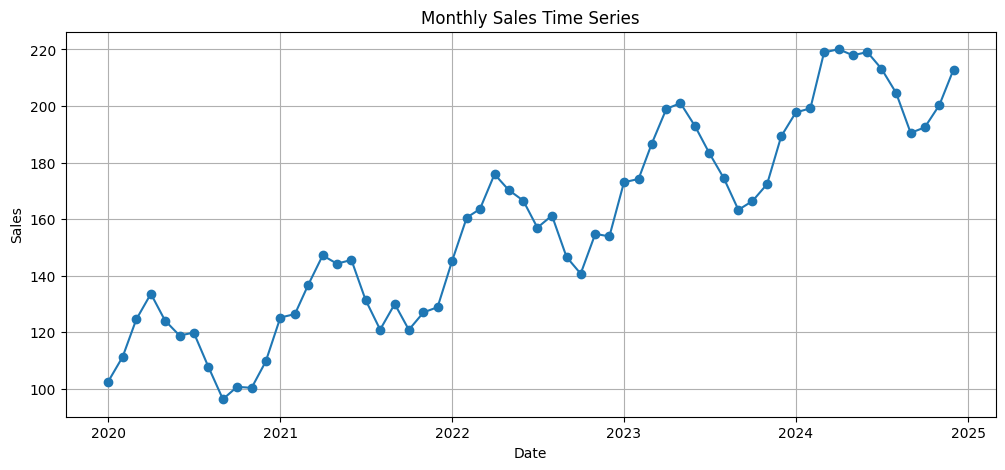

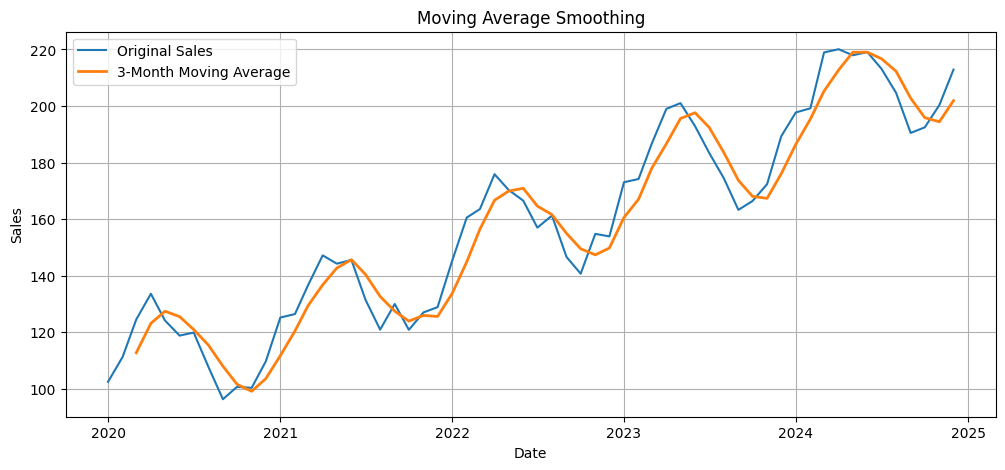

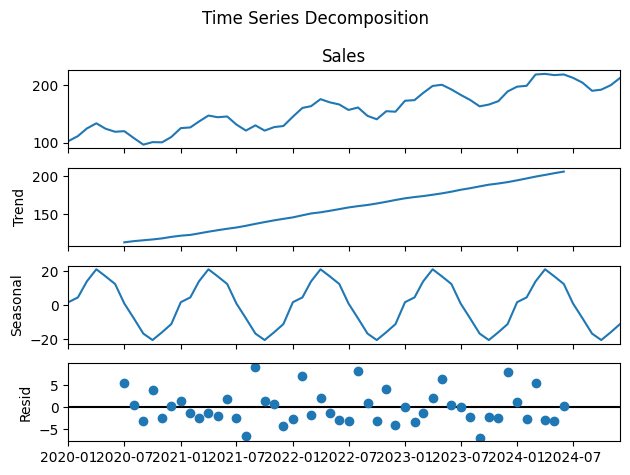


ADF TEST RESULTS
ADF Statistic: 1.1901260750369893
p-value: 0.9959169486856854
The series is non-stationary


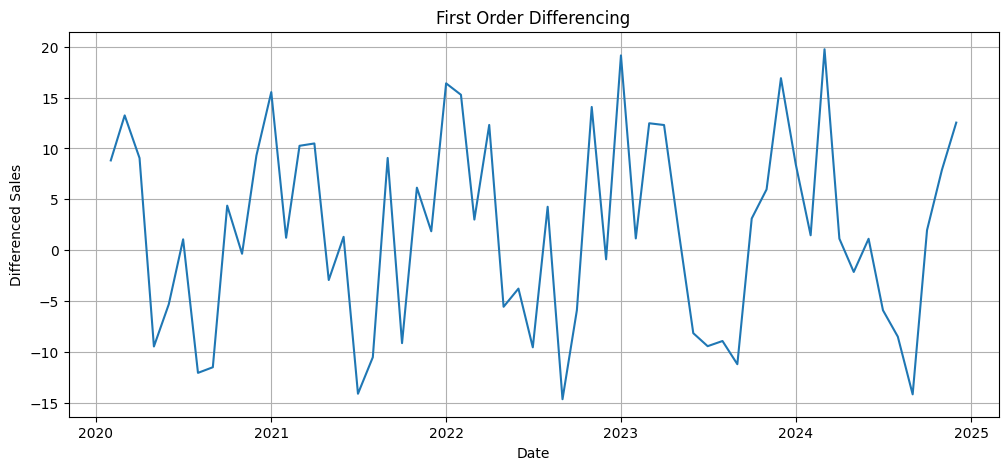


ADF TEST AFTER DIFFERENCING
ADF Statistic: -7.491611489643968
p-value: 4.490109821123952e-11
Differenced series is stationary


<Figure size 1000x400 with 0 Axes>

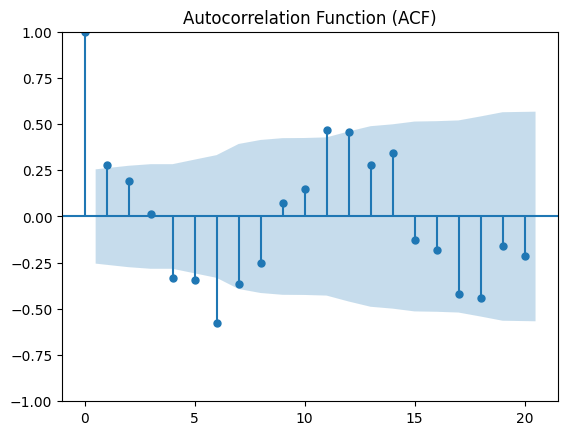

<Figure size 1000x400 with 0 Axes>

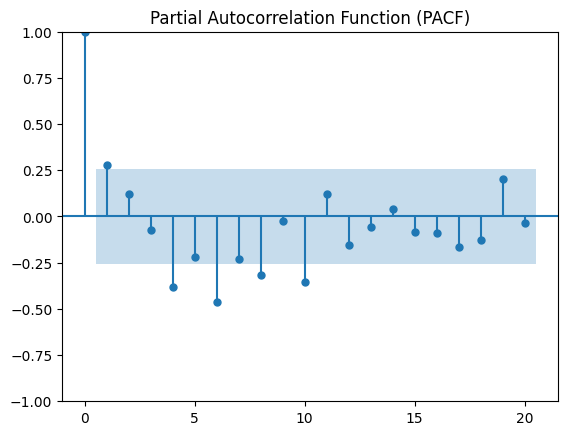


ARIMA MODEL SUMMARY
                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   48
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -171.550
Date:                Thu, 05 Nov 2026   AIC                            349.100
Time:                        04:52:13   BIC                            354.651
Sample:                    01-01-2020   HQIC                           351.189
                         - 12-01-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4971      0.445      1.118      0.264      -0.374       1.369
ma.L1         -0.2175      0.523     -0.416      0.677      -1.242       0.807
sigma2        86.4838     27.17

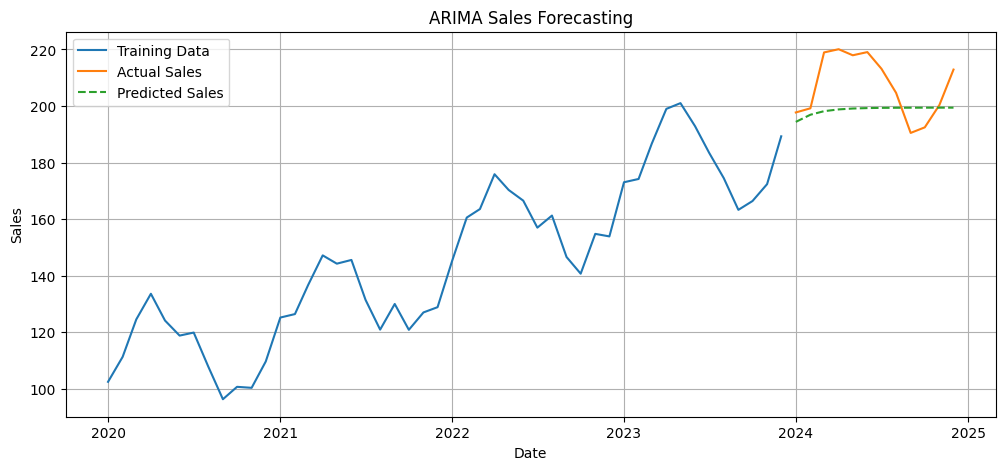


FORECASTING ACCURACY
MAE: 11.3
MSE: 181.27
RMSE: 13.46
MAPE: 5.32 %

NEXT 12 MONTHS FORECAST
            Forecasted_Sales
2025-01-01        217.076074
2025-02-01        219.162075
2025-03-01        220.198530
2025-04-01        220.713506
2025-05-01        220.969377
2025-06-01        221.096511
2025-07-01        221.159678
2025-08-01        221.191064
2025-09-01        221.206658
2025-10-01        221.214406
2025-11-01        221.218256
2025-12-01        221.220169


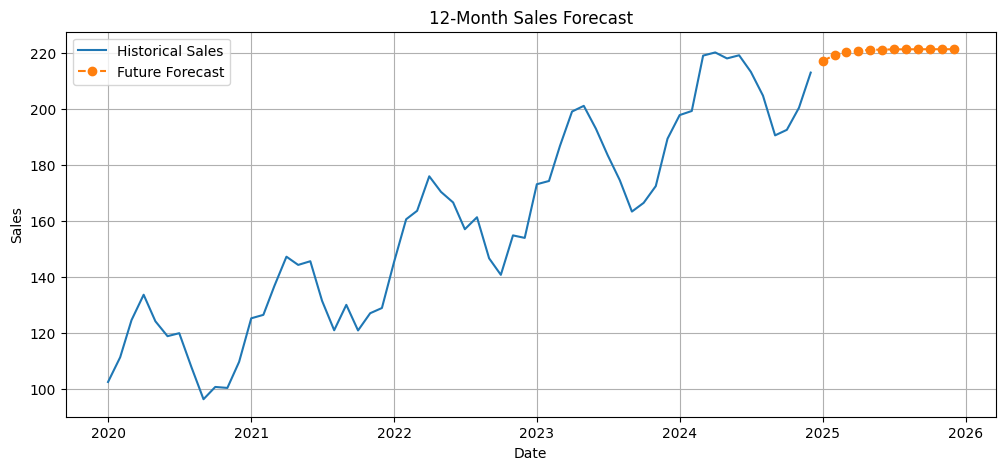

In [1]:
# -*- coding: utf-8 -*-
"""Untitled17.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1fvvsDNPyM_gLxt8flQh_zwRXhB-y6mvn
"""

!pip install pandas numpy matplotlib seaborn statsmodels scikit-learn

# ============================================
# TIME SERIES ANALYSIS USING PYTHON
# ============================================

# STEP 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings("ignore")


# STEP 2: Create Sample Time Series Dataset

np.random.seed(42)

dates = pd.date_range(
    start="2020-01-01",
    periods=60,
    freq="MS"
)

trend = np.arange(60) * 2

seasonality = 20 * np.sin(
    2 * np.pi * np.arange(60) / 12
)

noise = np.random.normal(0, 5, 60)

sales = 100 + trend + seasonality + noise

df = pd.DataFrame({
    "Date": dates,
    "Sales": sales
})

df.set_index("Date", inplace=True)

print("TIME SERIES DATA")
print(df.head())


# STEP 3: Visualize Time Series

plt.figure(figsize=(12, 5))

plt.plot(df.index, df["Sales"], marker="o")

plt.title("Monthly Sales Time Series")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.grid(True)
plt.show()


# STEP 4: Calculate Moving Average

df["Moving_Average"] = (
    df["Sales"].rolling(window=3).mean()
)

plt.figure(figsize=(12, 5))

plt.plot(df["Sales"], label="Original Sales")
plt.plot(
    df["Moving_Average"],
    label="3-Month Moving Average",
    linewidth=2
)

plt.title("Moving Average Smoothing")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(True)
plt.show()


# STEP 5: Time Series Decomposition

decomposition = seasonal_decompose(
    df["Sales"],
    model="additive",
    period=12
)

decomposition.plot()
plt.suptitle("Time Series Decomposition")
plt.tight_layout()
plt.show()


# STEP 6: Check Stationarity Using ADF Test

result = adfuller(df["Sales"])

print("\nADF TEST RESULTS")

print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] < 0.05:
    print("The series is stationary")
else:
    print("The series is non-stationary")


# STEP 7: First Order Differencing

df["Differenced"] = df["Sales"].diff()

plt.figure(figsize=(12, 5))

plt.plot(df["Differenced"])

plt.title("First Order Differencing")
plt.xlabel("Date")
plt.ylabel("Differenced Sales")

plt.grid(True)
plt.show()


# STEP 8: ADF Test After Differencing

diff_data = df["Differenced"].dropna()

result_diff = adfuller(diff_data)

print("\nADF TEST AFTER DIFFERENCING")

print("ADF Statistic:", result_diff[0])
print("p-value:", result_diff[1])

if result_diff[1] < 0.05:
    print("Differenced series is stationary")
else:
    print("Differenced series is non-stationary")


# STEP 9: Plot ACF

plt.figure(figsize=(10, 4))

plot_acf(diff_data, lags=20)

plt.title("Autocorrelation Function (ACF)")
plt.show()


# STEP 10: Plot PACF

plt.figure(figsize=(10, 4))

plot_pacf(diff_data, lags=20, method="ywm")

plt.title("Partial Autocorrelation Function (PACF)")
plt.show()


# STEP 11: Split Dataset into Training and Testing

train_size = int(len(df) * 0.8)

train = df["Sales"][:train_size]
test = df["Sales"][train_size:]


# STEP 12: Build ARIMA Model

model = ARIMA(
    train,
    order=(1, 1, 1)
)

model_fit = model.fit()

print("\nARIMA MODEL SUMMARY")

print(model_fit.summary())


# STEP 13: Forecast Future Values

forecast = model_fit.forecast(
    steps=len(test)
)

plt.figure(figsize=(12, 5))

plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, label="Actual Sales")
plt.plot(
    test.index,
    forecast,
    label="Predicted Sales",
    linestyle="--"
)

plt.title("ARIMA Sales Forecasting")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(True)
plt.show()


# STEP 14: Evaluate Forecasting Accuracy

mae = mean_absolute_error(test, forecast)

mse = mean_squared_error(test, forecast)

rmse = np.sqrt(mse)

mape = np.mean(
    np.abs((test - forecast) / test)
) * 100

print("\nFORECASTING ACCURACY")

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")


# STEP 15: Forecast Next 12 Months

final_model = ARIMA(
    df["Sales"],
    order=(1, 1, 1)
).fit()

future_forecast = final_model.forecast(steps=12)

future_dates = pd.date_range(
    start=df.index[-1] + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

future_df = pd.DataFrame({
    "Forecasted_Sales": future_forecast.values
}, index=future_dates)

print("\nNEXT 12 MONTHS FORECAST")

print(future_df)

plt.figure(figsize=(12, 5))

plt.plot(
    df.index,
    df["Sales"],
    label="Historical Sales"
)

plt.plot(
    future_df.index,
    future_df["Forecasted_Sales"],
    label="Future Forecast",
    marker="o",
    linestyle="--"
)

plt.title("12-Month Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(True)
plt.show()